### [GALT] Vežba 4: galpy

Za početak, potrebno je instaliraty gaply biblioteku: https://docs.galpy.org/en/v1.12.1/

Za nedoumice, pogledati i rad: https://iopscience.iop.org/article/10.1088/0067-0049/216/2/29/pdf

### <font color='yellow'> Ideja vežbe: implementacija funkcija iz galpy biblioteke, s ciljem analiziranja orbitalne dinamike u galaktičkom potencijalu</font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

Prošli čas smo odredili Galaktički potencijal rešavanjem Poasonove jednačine, gde smo uzeli da naša galaksija ima samo jednu komponentu - zvezdani disk. Međutim, u realnosti to nije slučaj. Jedan od najjednostavnijih modela koji se često koristi jeste onaj koji uračunava _bulge_, disk (_thin and thick disk_ ili neki usrednjeni) i halo tamne materije. U tom slučaju, svaku od komponenti opišemo nekom funkcijom, i saberemo. Međutim, u zavisnosti od toga šta radimo, mogu nam biti potrebni i složeniji modeli. Npr. model diska uglavnom zanemaruje spiralne grane i pretpostavlja azimutalnu simetriju, tako da možemo to da uračunamo, ili centralnu prečku (_bar_), ili međuzvezdanu materiju, ili... 

U samoj galpy biblioteci, postoji dosta različitih potencijala, između ostalog i neki koji se zovu MW... Hajde da pogledamo jedan od njih.

In [1]:
from galpy.potential import MWPotential2014

In [2]:
print(MWPotential2014)

CompositePotential of 3 potentials:
	PowerSphericalPotentialwCutoff with internal parameters: amp=0.0299945971882183, alpha=1.8, rc=0.2375
	MiyamotoNagaiPotential with internal parameters: amp=0.7574802019371595, a=0.375, b=0.035
	NFWPotential with internal parameters: amp=4.852230533527998, a=2.0
and physical outputs off


Ovde vidite kako je definisan taj potencijal, tj. zbir kojih komponenata je.

##### <font color="green">1. Provjeriti u dokumentaciji (i napisati u nastavku) šta koja od komponenata predstavlja i kakvom funkcijom je opisana. </font>

Као што се види из принта изнад, ово је 3Д потенцијал кога сачињавају: PowerSphericalPotentialwCutoff, MiyamotoNagaiPotential и NFWPotential.
1. PowerSphericalPotentialwCutoff је закон облика: $\rho(r) = \mathrm{amp} * (\frac{r_1}{r})^\alpha * e^{-(\frac{r}{r_c})^2}$;
2. MiyamotoNagaiPotential је закон облика: $\Phi(R,z) = -\frac{\mathrm{amp}}{\sqrt{R^2+(a+\sqrt{z^2+b^2})^2}}$;
3. NFWPotential је закон облика: $ \rho(r) = \frac{\mathrm{amp}}{4\pi a^3} *\frac{1}{\frac{r}{a}*(1+\frac{r}{a})^2}$

У сва три ознака $\mathrm{amp}$ представља производ $\mathrm{GM}$ у овом случају, но главно је да је то амплитуда за потенцијал. Први чинилац је сферно симетричан са степеним законом густине и експоненцијалним одсијецањем на великим растојањима. У овом моделу представља балџ. Други чинилац описује потенцијал у координатама R (вектор положаја) и координата z (управна на галактичку раван, као и у Декартову систему). Има и а и b за параметре који, редом, дају скалу дужине и висине. Овај члан описује диск галаксије. Трећи чинилац потенцијал је, поново, функција густине, а овдје ознака а описује скалу полупречника. Представља хало тамне материје за овај модел.


##### <font color="green">2. Prikazati krivu rotacije (možete koristiti vcirc funkciju). Obratiti pažnju u kojim jedinicama su v i r (i generalno promenljive u galpy) i prebaciti u [km/s], a R[kpc]. </font>

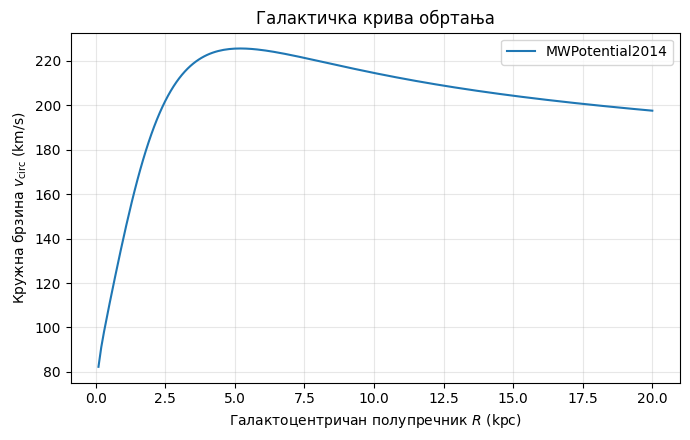

In [3]:
#Приказивање криве ротације функцијом vcirc
import astropy.units as u
import galpy as gp
from galpy.potential import MWPotential2014, vcirc
import matplotlib.pyplot as plt
import numpy as np

R = np.linspace(0.1, 20.0, 200) * u.kpc
кружне_брзине = vcirc(MWPotential2014, R, ro=8.0 * u.kpc, vo=220.0 * u.km / u.s)
plt.figure(figsize=(7, 4.5))
plt.plot(R.to_value(u.kpc), кружне_брзине, label="MWPotential2014")
plt.xlabel("Галактоцентричан полупречник $R$ (kpc)")
plt.ylabel(r"Кружна брзина $v_{\mathrm{circ}}$ (km/s)")
plt.title("Галактичка крива обртања")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Ово је зависност кружне брзине од галактоцентричног растојања за потенцијал MWPotential2014. Уочава се да кружна брзина у почетку расте, достиже максимум, а затим се са повећањем растојања постепено смањује, при чему је у спољашњим дијеловима Галаксије промјена знатно блажа. Оваква зависност одражава заједнички гравитациони утицај балџа, диска и халоа тамне материје - главни примјер потребе за увођењем тамне материје у теорију.

##### <font color="green">3. Pokazati doprinos svake komponente odvojeno MWPotential2014 u krivoj sjaja. Kakvu situaciju imamo ovde u odnosu na rotacionu krivu koju smo videli prošli čas? </font>

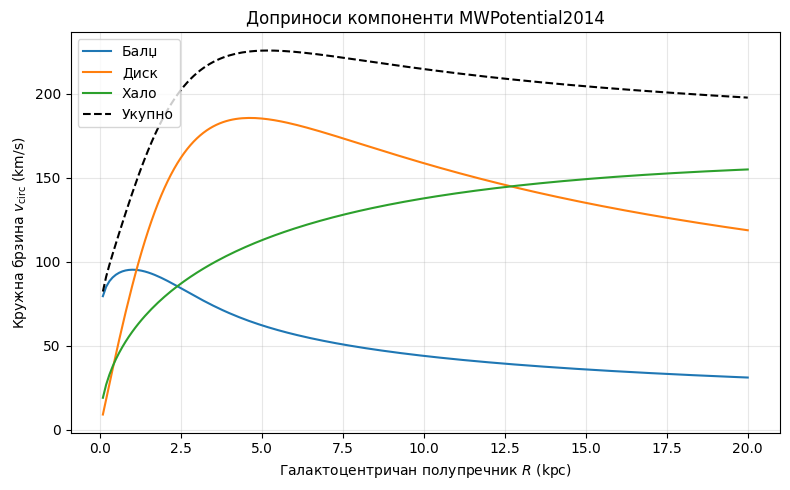

In [6]:
R = np.linspace(0.1, 20.0, 200) * u.kpc
компоненте = [MWPotential2014[0], MWPotential2014[1], MWPotential2014[2]]
називи = ["Балџ", "Диск", "Хало"]

plt.figure(figsize=(8, 5))
for компонента, назив in zip(компоненте, називи):
    v = vcirc(компонента, R, ro=8.0*u.kpc, vo=220.0*u.km/u.s)
    plt.plot(R.to_value(u.kpc), v, label=назив)

v_укупно = vcirc(MWPotential2014, R, ro=8.0*u.kpc, vo=220.0*u.km/u.s)
plt.plot(R.to_value(u.kpc), v_укупно, "k--", label="Укупно")

plt.xlabel("Галактоцентричан полупречник $R$ (kpc)")
plt.ylabel(r"Кружна брзина $v_{\mathrm{circ}}$ (km/s)")
plt.title("Доприноси компоненти MWPotential2014")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Овдје можемо примјетити да, како се одаљавамо од средишта Галаксије, да различити чиниоци дају највећи допринос самом потенцијалу. У првом килопарсеку (отприлике) главни потенцијал долази од балџа, на средњим растојањима главно даје диск, док у задњем дијелу (што је био и узрок да се уведе модел халоа тамне материје) највише доприноси хало те он прави плато за укупан потенцијал у задњем дијелу гдје би луминозна материја требала да даје опадајућу функцију. Као што ће се видјети у наставку, доприноси преко квадрата кружне брзине, тј. сабирају се квадрати кружних брзина и доминантан члан у овом дијелу потиче од потенцијала халоа тамне материје.

##### <font color="green">4. Obzirom da se potencijali sabiraju, da li se i brzine na određenom R sabiraju na isti način ili nekako drugačije? </font>

In [ ]:
#Прилажем и један нумерички доказ за извлачење доњег закључка
v_балџ = vcirc(MWPotential2014[0], R, ro=8.0*u.kpc, vo=220.0*u.km/u.s)
v_диск = vcirc(MWPotential2014[1], R, ro=8.0*u.kpc, vo=220.0*u.km/u.s)
v_хало = vcirc(MWPotential2014[2], R, ro=8.0*u.kpc, vo=220.0*u.km/u.s)
v_сабирање = np.sqrt(v_балџ**2 + v_диск**2 + v_хало**2)

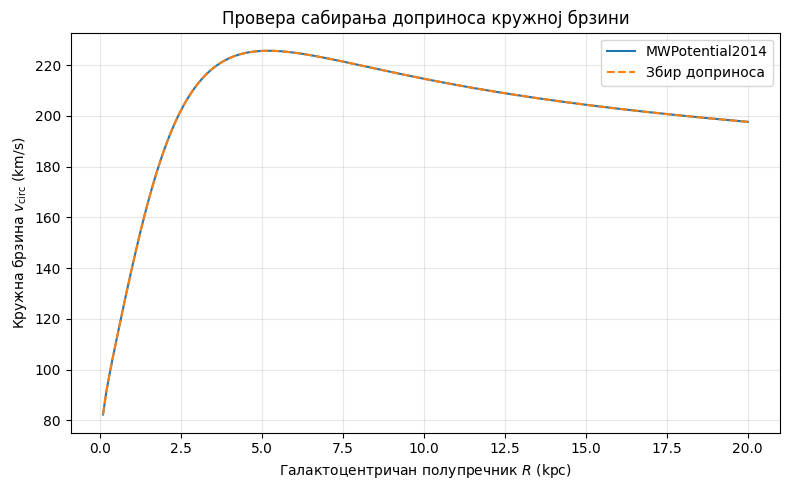

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(R.to_value(u.kpc), кружне_брзине, label="MWPotential2014")
plt.plot(R.to_value(u.kpc), v_сабирање, "--", label="Збир доприноса")
plt.xlabel("Галактоцентричан полупречник $R$ (kpc)")
plt.ylabel(r"Кружна брзина $v_{\mathrm{circ}}$ (km/s)")
plt.title("Провера сабирања доприноса кружној брзини")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

За разлику потенцијала, овдје се питагорејски сабирају кружне брзине, тј. квадрат укупне кружне брзине је једнак збиру квадрата појединачних доприноса кружних брзина. Ваља имати у глави и да је позната веза: $v_c^2 = \mathrm{R}\frac{dΦ}{dR}$. Извод је линеаран оператор, те пролази кроз сабирање без промјена ----> распише се збир појединачних чинилаца потенцијала и онда је сваки за себе квадрат одговарајуће кружне брзине. Овим је показано да је ова веза питагорејска облика између чинилаца и укупне кружне брзине.

##### <font color="green">5. Koristeći funkciju Orbit, integraliti kretanje Sunca u Galaktičkom potenciju i prikazati u x-y ravni. </font>

Uzeti da je u početnom trenutku vR=0, a vT iz rotacione krive za R Sunca. Takođe, možemo uzeti z=0, vz=0 i phi=0.

In [11]:
#Почетни услови
vR = 0
z = 0
vz = 0
φ = 0
R_сунца = 8.0 * u.kpc
vT = vcirc(MWPotential2014, R_сунца, ro=8.0*u.kpc, vo=220.0*u.km/u.s)
print(f"Трансферзалан чинилац брзине Сунца је: {vT:.2f} km/s")

Трансферзалан чинилац брзине Сунца је: 220.00 km/s


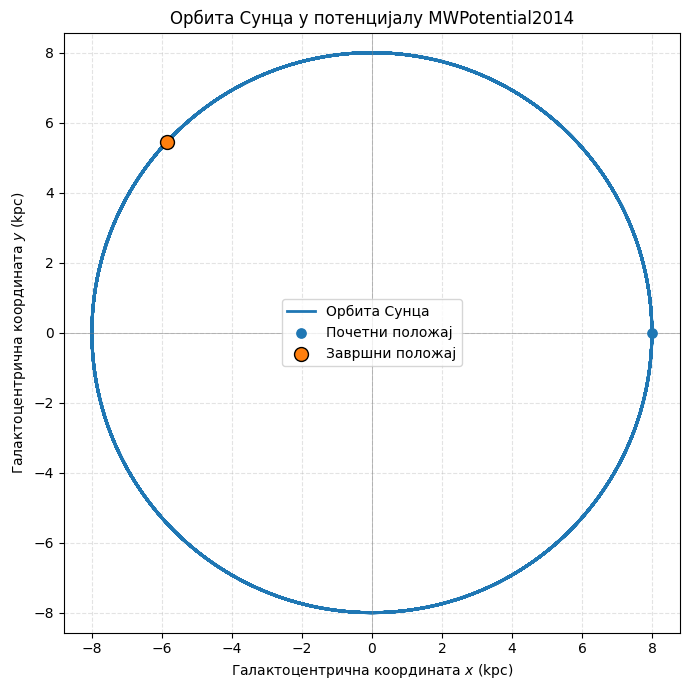

In [20]:
from galpy.orbit import Orbit
Сунце = Orbit([1.0, vR, vT/220.0, z, vz, φ], ro=8.0, vo=220.0)
t_јединица = (8.0*u.kpc / (220.0*u.km/u.s)).to_value(u.Gyr)
t = np.linspace(0, 5/t_јединица, 2000) #Нека интеграција траје 5 милијарди година
Сунце.integrate(t, MWPotential2014, method="odeint")
#Приказ орбите Сунца
путања = Сунце.getOrbit()
x = 8.0*путања[:, 0]*np.cos(путања[:, 5])
y = 8.0*путања[:, 0]*np.sin(путања[:, 5])
plt.figure(figsize=(7, 7))
plt.plot(x, y, linewidth=2, label="Орбита Сунца")
plt.scatter(x[0], y[0], s=45, marker="o", label="Почетни положај", zorder=3)
plt.scatter(x[-1], y[-1], s=100, marker="o", edgecolors="black", linewidths=1, label="Завршни положај", zorder=4)
plt.xlabel("Галактоцентрична координата $x$ (kpc)")
plt.ylabel("Галактоцентрична координата $y$ (kpc)")
plt.title("Орбита Сунца у потенцијалу MWPotential2014")
plt.grid(True, linestyle="--", alpha=0.35)
plt.axhline(0, color="gray", linewidth=0.7, alpha=0.5)
plt.axvline(0, color="gray", linewidth=0.7, alpha=0.5)
plt.axis("equal")
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

Интеграцијом кретања Сунца у потенцијалу MWPotential2014, за почетно галактоцентрично растојање од 8 kpc и трансверзалну брзину од 220 km/s, добија се приближно кружна орбита у галактичкој равни. Овакав резултат се дао очекивати, будући да је почетна трансферзална брзина изједначена са кружном брзином добијеном из ротационе криве за дато растојање. Током интеграције од пет милијарди година галактоцентрично растојање остаје практично непромијењено, док се мијења азимуталан положај Сунца.

##### <font color="green">6. Proveriti šta se dešava ako vT iz prethodnog slučaja pomnožimo sa 0.8 i sa 1.2. Uporediti ova tri rezultata. Nacrtati orbite u sva tri slučaja na jednom grafiku u x-y ravni i iskomentarisati. </font>

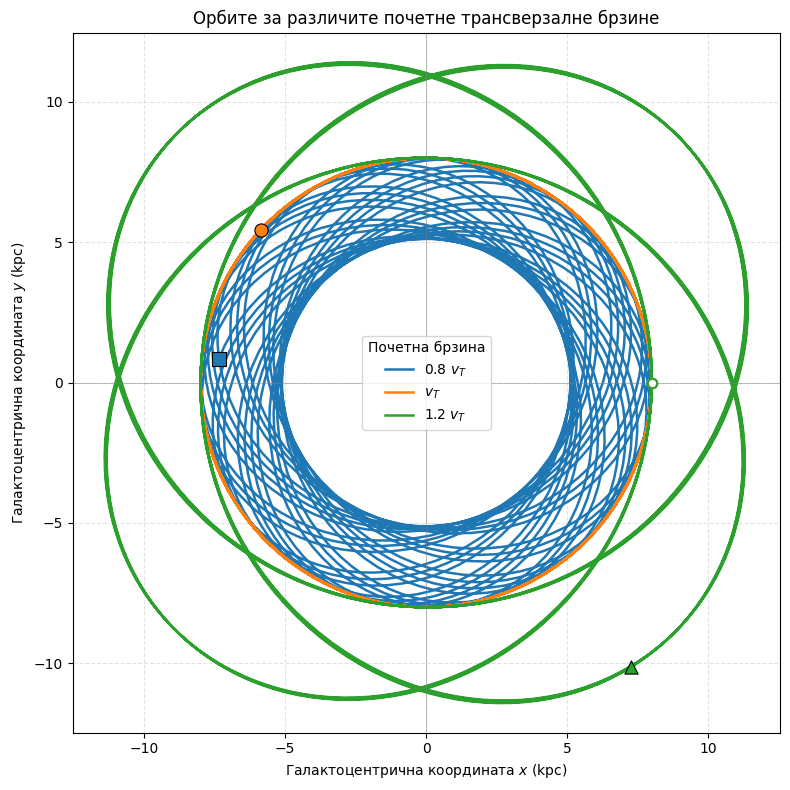

In [ ]:
#Почетни услови и дефинисање орбита
Сунце = Orbit([1.0, 0, vT/220.0, 0, 0, 0], ro=8.0, vo=220.0)
Сунце_08 = Orbit([1.0, 0, 0.8*vT/220.0, 0, 0, 0], ro=8.0, vo=220.0)
Сунце_12 = Orbit([1.0, 0, 1.2*vT/220.0, 0, 0, 0], ro=8.0, vo=220.0)
орбите = [Сунце_08, Сунце, Сунце_12]
називи = ["0.8 $v_T$", "$v_T$", "1.2 $v_T$"]
for орбита in орбите:
    орбита.integrate(t, MWPotential2014)
#Приказ орбита за три различите трансверзалне брзине
маркери = ["s", "o", "^"]
plt.figure(figsize=(8, 8))
for орбита, назив, маркер in zip(орбите, називи, маркери):
    путања = орбита.getOrbit()
    x = 8.0*путања[:, 0]*np.cos(путања[:, 5])
    y = 8.0*путања[:, 0]*np.sin(путања[:, 5])
    линија, = plt.plot(x, y, linewidth=1.8, label=назив)
    боја = линија.get_color()
    plt.scatter(x[0], y[0], s=45, marker="o", facecolors="white", edgecolors=боја, linewidths=1.5, zorder=3)
    plt.scatter(x[-1], y[-1], s=90, marker=маркер, color=боја, edgecolors="black", linewidths=0.8, zorder=4)
plt.xlabel("Галактоцентрична координата $x$ (kpc)")
plt.ylabel("Галактоцентрична координата $y$ (kpc)")
plt.title("Орбите за различите почетне трансверзалне брзине")
plt.grid(True, linestyle="--", alpha=0.35)
plt.axhline(0, color="gray", linewidth=0.7, alpha=0.5)
plt.axvline(0, color="gray", linewidth=0.7, alpha=0.5)
plt.axis("equal")
plt.legend(title="Почетна брзина", frameon=True)
plt.tight_layout()
plt.show()

1. Случај $(v_T'=0.8v_T)$:

Почетна трансверзална брзина је мања од кружне брзине на растојању Сунца од галактичког центра; звијезда зато нема довољно угаоног момента да одржава кружну орбиту на почетном растојању. Орбита постаје израженије елиптична, са мањим перицентром и већим ексцентрицитетом. Сунце се, стога, креће ка унутрашњим дијеловима Галаксије, те затим поново ка спољашњим.

2. Случај $(v_T'=v_T)$:

Почетна трансверзална брзина одговара кружној брзини добијеној из ротационе криве. Пошто су почетна радијална брзина и вертикална брзина једнаке нули, очекује се приближно кружна орбита што је и добијено на графику. Растојање од галактичког центра такође остаје приближно константно, па је ексцентрицитет близак нули.

3. Случај $(v_T'=1.2v_T)$:

Почетна трансверзална брзина је већа од кружне брзине. Тијело има већи угаони момент и креће се по елиптичној орбити која га одводи на већа галактоцентрична растојања. Почетни положај одговара перицентру орбите, док је апоцентар на већем растојању. Ексцентрицитет је већи него у основном случају.
За случај $(0.8v_T)$, почетни положај је апоцентар, а за $(1.2v_T)$ перицентар. Ваља нагласити јер су почетне радијалне брзине у оба случаја нула.

Заједнички закључак: Промјена почетне трансверзалне брзине значајно утиче на облик орбите. Брзина мања од кружне доводи до кретања по орбити са мањим перицентром, док већа брзина доводи до орбите са већим апоцентром. Основни случај представља приближно кружну орбиту.

##### <font color="green">7. Naći pericentar, apocentar i ekscentricitet za svaku od ove tri orbite. </font>

In [29]:
#Одређивање перицента, апоцентра и ексцентрицитета
for орбита, назив in zip(орбите, називи):
    r_peri = орбита.rperi()
    r_apo = орбита.rap()
    e = орбита.e()
    print(f"{назив}:")
    print(f"  Перицентар: {r_peri:.3f} kpc")
    print(f"  Апоцентар: {r_apo:.3f} kpc")
    print(f"  Ексцентрицитет: {e:.4f}")

0.8 $v_T$:
  Перицентар: 5.119 kpc
  Апоцентар: 8.000 kpc
  Ексцентрицитет: 0.2196
$v_T$:
  Перицентар: 8.000 kpc
  Апоцентар: 8.000 kpc
  Ексцентрицитет: 0.0000
1.2 $v_T$:
  Перицентар: 8.000 kpc
  Апоцентар: 12.521 kpc
  Ексцентрицитет: 0.2203


За орбиту са почетном трансверзалном брзином $(0.8v_T)$ добијен је перицентар од приближно 5.12 kpc и апоцентар од 8 kpc, уз ексцентрицитет од 0.2196. У случају почетне кружне брзине, перицентар и апоцентар су једнаки и износе 8 kpc, што одговара кружној орбити са ексцентрицитетом једнаким нули. За почетну брзину $(1.2v_T)$ перицентар износи 8 kpc, док је апоцентар приближно 12.52 kpc, уз ексцентрицитет од 0.2203. Добијени резултати показују да повећање почетне трансверзалне брзине доводи до веће удаљености од галактичког центра, док њено смањење омогућава кретање на мањим галактоцентричним растојањима.